# 干豆分类与特征选择：课程实验

**选题：干豆品种分类中的特征精简：分类性能、类别差异与选择稳定性分析。**

这份notebook就是整个作业的操作入口。按顺序运行：**读数据 → 看数据 → 比较模型 → 选特征 → 测试 → 保存与预测**。

我们只研究一个小问题：原来有16个特征，保留4、8或12个后，能否仍然分得比较准？

在VS Code右上角选择本项目的`.venv`内核，再点“全部运行”；也可以按Shift+Enter逐格阅读。输出已保留，首次阅读不用急着重跑。

## 1. 准备工具和参数

pandas负责表格，matplotlib负责画图，scikit-learn负责机器学习。`RANDOM_SEED`固定随机过程，便于复现。所有路径都从项目目录计算。

In [1]:
from pathlib import Path
from datetime import datetime
from functools import partial
from itertools import combinations
import sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits

PROJECT_DIRECTORY = next(path for path in [Path.cwd(), Path.cwd().parent]
                         if (path / "data_loader.py").is_file())
sys.path.insert(0, str(PROJECT_DIRECTORY))
from data_loader import load_dry_bean_data, DATA_SHA256

RANDOM_SEED = 20261025
FEATURE_COUNTS = [4, 8, 12, 16]
NUMBER_OF_FOLDS = 5
F1_TOLERANCE = 0.01
run_id = datetime.now().strftime("%Y%m%d")
data_directory = PROJECT_DIRECTORY / "data"
results_directory = PROJECT_DIRECTORY / "results"
figures_directory = results_directory / "figures"
models_directory = PROJECT_DIRECTORY / "models"
for directory in [data_directory, results_directory, figures_directory, models_directory]:
    directory.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans"],
                     "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "pdf.fonttype": 42, "svg.fonttype": "none", "legend.frameon": False})
print("本次实验：", run_id, "；随机种子：", RANDOM_SEED)

本次实验： 20261025 ；随机种子： 20261025


In [2]:
# 这三个小函数只负责保存文件和显示进度，不包含模型训练。
def save_figure(figure, filename):
    figure.savefig(figures_directory / filename, dpi=600)

def save_results(table, filename):
    table = table.copy()
    table.insert(0, "run_id", run_id)
    path = results_directory / filename
    # 重跑时追加指标记录，不产生一批新的结果目录。
    table.to_csv(path, mode="a", header=not path.exists(), index=False)

def log_progress(message):
    print(message)
    with (results_directory / "training_log.txt").open("a", encoding="utf-8") as file:
        file.write(f"[{run_id}] {message}\n")

started_at = time.perf_counter()
log_progress(f"开始实验，seed={RANDOM_SEED}，5折；LR的C=1，KNN邻居数=5，RF树数=100")

开始实验，seed=20261025，5折；LR的C=1，KNN邻居数=5，RF树数=100


## 2. 读取、清洗并划分数据

一行是一粒干豆，16个数值特征描述形状，`Class`是品种。先删除输入完全相同的重复行，避免相同样本同时出现在训练和测试中。

这里把80%作为开发集，用来训练和选择特征；20%作为测试集，留到最后评价。`stratify`让两个集合的类别比例接近。标准化和特征排名都还没有开始。

In [3]:
raw_data = load_dry_bean_data(data_directory)
feature_names = raw_data.columns.drop("Class").tolist()
print("原始数据形状：", raw_data.shape)
print("缺失值数量：", raw_data.isna().sum().sum())
# 相同输入如果对应不同标签，就不能悄悄保留其中一个标签。
assert raw_data.groupby(feature_names)["Class"].nunique().max() == 1
clean_data = raw_data.drop_duplicates(subset=feature_names).copy()
clean_data.index.name = "sample_id"
print("删除重复行：", len(raw_data) - len(clean_data))

features = clean_data[feature_names]
labels = clean_data["Class"]
features_development, features_test, labels_development, labels_test = train_test_split(
    features, labels, test_size=0.2, stratify=labels, random_state=RANDOM_SEED)
class_names = sorted(labels_development.unique())
print("开发集：", len(features_development), "；测试集：", len(features_test))
display(clean_data.head())
display(features_development.describe().T.round(3))

splitter = StratifiedKFold(n_splits=NUMBER_OF_FOLDS, shuffle=True, random_state=RANDOM_SEED)
folds = list(splitter.split(features_development, labels_development))
clean_data["split"] = "test"
clean_data.loc[features_development.index, "split"] = "development"
clean_data["cv_fold"] = -1
for fold_number, (_, validation_indices) in enumerate(folds, start=1):
    clean_data.loc[features_development.iloc[validation_indices].index, "cv_fold"] = fold_number
clean_data.to_csv(data_directory / "dry_bean_clean.csv")

原始数据形状： (13611, 17)
缺失值数量： 0
删除重复行： 68
开发集： 10834 ；测试集： 2709


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
sample_id,,,,,,,,,,,,,,,,,
0,28395.0,610.291,208.178117,173.888747,1.197191,0.549812,28715.0,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734.0,638.018,200.524796,182.734419,1.097356,0.411785,29172.0,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380.0,624.110,212.826130,175.931143,1.209713,0.562727,29690.0,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008.0,645.884,210.557999,182.516516,1.153638,0.498616,30724.0,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140.0,620.134,201.847882,190.279279,1.060798,0.333680,30417.0,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


,count,mean,std,min,25%,50%,75%,max
Area,10834.0,53080.372,29468.882,20464.000,36222.250,44559.000,61496.750,251432.000
Perimeter,10834.0,855.179,215.204,524.736,702.970,793.896,977.342,1921.685
MajorAxisLength,10834.0,319.988,85.978,183.965,253.204,296.444,376.521,738.145
MinorAxisLength,10834.0,202.373,45.167,129.748,175.900,192.567,217.320,460.198
AspectRation,10834.0,1.581,0.245,1.025,1.432,1.550,1.704,2.389
Eccentricity,10834.0,0.751,0.092,0.219,0.716,0.764,0.810,0.908
ConvexArea,10834.0,53799.301,29919.119,20772.000,36612.750,45109.000,62457.250,257425.000
EquivDiameter,10834.0,253.079,59.459,161.417,214.755,238.190,279.822,565.803
Extent,10834.0,0.750,0.049,0.555,0.719,0.760,0.787,0.866
Solidity,10834.0,0.987,0.005,0.919,0.986,0.988,0.990,0.995


## 3. 先看看数据

只画开发集。类别数量不完全相同，因此除了准确率，还使用**宏F1**：先算每一类的F1，再取平均，使小类别也受到关注。相关性热图帮助观察哪些形状特征包含相似信息。

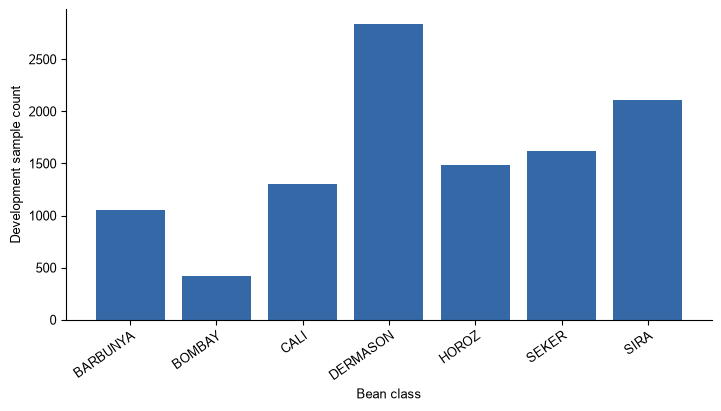

In [4]:
class_counts = labels_development.value_counts().reindex(class_names)
figure, axis = plt.subplots(figsize=(7.1, 4.0), layout="constrained")
axis.bar(class_counts.index, class_counts.values, color="#3568A6")
axis.set(xlabel="Bean class", ylabel="Development sample count")
plt.setp(axis.get_xticklabels(), rotation=35, ha="right", rotation_mode="anchor")
save_figure(figure, "class_distribution.png")
plt.show()

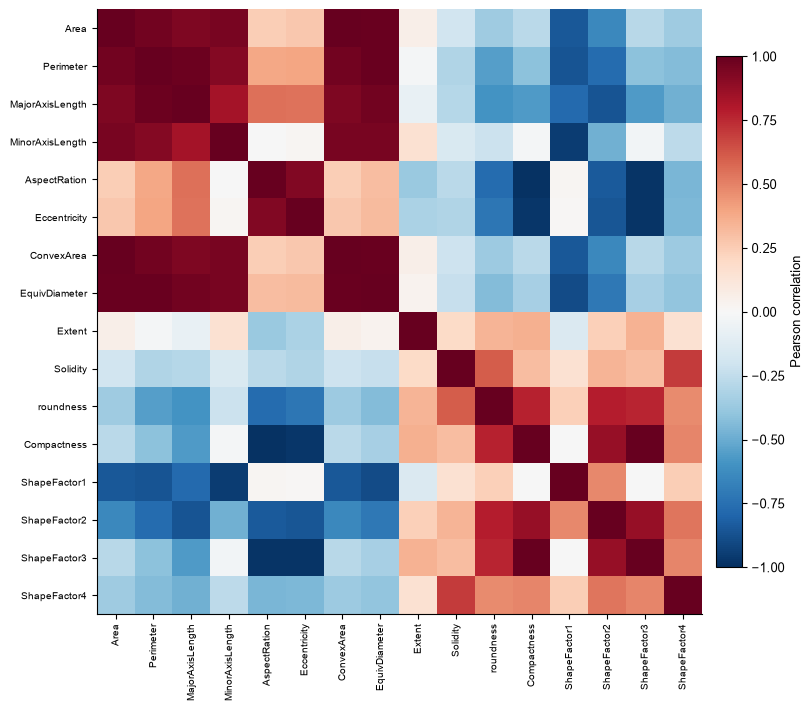

In [5]:
correlations = features_development.corr()
figure, axis = plt.subplots(figsize=(8.4, 7.0), layout="constrained")
image = axis.imshow(correlations, cmap="RdBu_r", vmin=-1, vmax=1)
figure.colorbar(image, ax=axis, fraction=0.035, pad=0.02, label="Pearson correlation")
axis.set(xticks=range(16), yticks=range(16), xticklabels=feature_names, yticklabels=feature_names)
plt.setp(axis.get_xticklabels(), rotation=90, ha="right", va="center", rotation_mode="anchor", fontsize=7.5)
plt.setp(axis.get_yticklabels(), fontsize=7.5)
save_figure(figure, "feature_correlation.png")
plt.show()

## 4. 模型如何训练

主模型是逻辑回归（LR）和K近邻（KNN）。先固定常用参数，避免同时学习过多调参细节；随机森林（RF）和多数类预测（Dummy）在最后作为参照。

`Pipeline`把步骤串起来：**标准化 → 选特征（可选）→ 分类**。每一折只对训练部分调用`fit`，验证和测试只调用`predict`，这样不会把测试信息提前泄漏给模型。

互信息（MI）给每个特征一个与类别有关的分数，`SelectKBest`保留分数较高的若干列。保留全部16列时不需要筛选。

In [6]:
def create_model(model_name, number_of_features=None):
    classifiers = {
        "LR": LogisticRegression(C=1.0, max_iter=2000, random_state=RANDOM_SEED),
        "KNN": KNeighborsClassifier(n_neighbors=5),
        "RF": RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED, n_jobs=2),
        "Dummy": DummyClassifier(strategy="most_frequent")}
    steps = [("scale", StandardScaler())]
    if number_of_features is not None:
        score_function = partial(mutual_info_classif, random_state=RANDOM_SEED)
        steps.append(("select", SelectKBest(score_func=score_function, k=number_of_features)))
    steps.append(("classifier", classifiers[model_name]))
    return Pipeline(steps)

## 5. 用5折交叉验证比较特征数量

把开发集轮流分成5份：4份训练、1份验证。LR和KNN各比较4、8、12、16个特征，共8组、40次拟合。下面的循环就是训练过程，结果直接打印在这里。

每次验证的参数、分数、选中特征会记入CSV；逐样本预测集中压缩到一个文件，不生成几十个小文件。

In [7]:
validation_records = []
validation_predictions = {}
selected_feature_sets = {count: [] for count in FEATURE_COUNTS if count < 16}

with threadpool_limits(limits=2):
    for model_name in ["LR", "KNN"]:
        for count in FEATURE_COUNTS:
            fold_scores = []
            for fold_number, (training_indices, validation_indices) in enumerate(folds, start=1):
                model = create_model(model_name, None if count == 16 else count)
                model.fit(features_development.iloc[training_indices], labels_development.iloc[training_indices])
                predicted = model.predict(features_development.iloc[validation_indices])
                actual = labels_development.iloc[validation_indices]
                score = f1_score(actual, predicted, average="macro")
                fold_scores.append(score)
                chosen_features = (np.array(feature_names)[model.named_steps["select"].get_support()].tolist()
                                   if count < 16 else feature_names)
                if model_name == "LR" and count < 16:
                    selected_feature_sets[count].append(chosen_features)
                validation_records.append({"model": model_name, "selection": "MI" if count < 16 else "All",
                    "feature_count": count, "fold": fold_number, "seed": RANDOM_SEED, "subset_seed": -1,
                    "accuracy": accuracy_score(actual, predicted), "macro_f1": score,
                    "features": "|".join(chosen_features)})
                key = f"{model_name}_{count}_fold_{fold_number}"
                validation_predictions[key + "_ids"] = actual.index.to_numpy()
                validation_predictions[key + "_true"] = actual.to_numpy(dtype=str)
                validation_predictions[key + "_predicted"] = predicted.astype(str)
            log_progress(f"{model_name}，{count:2d}个特征，5折宏F1：{np.mean(fold_scores):.4f}")

validation_table = pd.DataFrame(validation_records)
save_results(validation_table, "cross_validation_results.csv")
np.savez_compressed(results_directory / "validation_predictions.npz", **validation_predictions)
model_comparison = validation_table.groupby(["model", "feature_count"], as_index=False).agg(
    macro_f1=("macro_f1", "mean"), fold_std=("macro_f1", "std"), accuracy=("accuracy", "mean"))
save_results(model_comparison, "model_comparison.csv")
display(model_comparison.round(4))

LR， 4个特征，5折宏F1：0.7986
LR， 8个特征，5折宏F1：0.9208
LR，12个特征，5折宏F1：0.9225
LR，16个特征，5折宏F1：0.9352
KNN， 4个特征，5折宏F1：0.8126
KNN， 8个特征，5折宏F1：0.9186
KNN，12个特征，5折宏F1：0.9122
KNN，16个特征，5折宏F1：0.9321


,model,feature_count,macro_f1,fold_std,accuracy
0,KNN,4,0.8126,0.0071,0.8140
1,KNN,8,0.9186,0.0031,0.9074
2,KNN,12,0.9122,0.0036,0.9018
3,KNN,16,0.9321,0.0018,0.9188
4,LR,4,0.7986,0.0129,0.8008
5,LR,8,0.9208,0.0042,0.9086
6,LR,12,0.9225,0.0042,0.9098
7,LR,16,0.9352,0.0053,0.9235


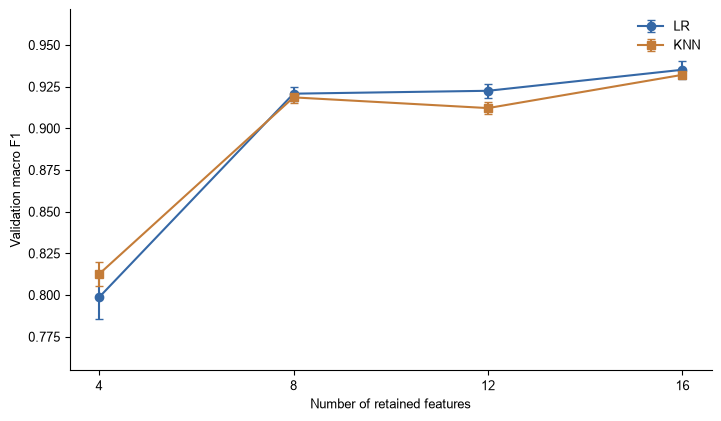

误差条是5折分数的标准差，只描述划分波动，不是独立实验置信区间。


In [8]:
figure, axis = plt.subplots(figsize=(7.1, 4.1), layout="constrained")
for model_name, color, marker in [("LR", "#3568A6", "o"), ("KNN", "#C47C38", "s")]:
    rows = model_comparison[model_comparison["model"] == model_name]
    axis.errorbar(rows["feature_count"], rows["macro_f1"], yerr=rows["fold_std"],
                  label=model_name, color=color, marker=marker, capsize=3)
axis.set(xlabel="Number of retained features", ylabel="Validation macro F1", xticks=FEATURE_COUNTS)
axis.legend()
axis.margins(y=0.2)
save_figure(figure, "feature_count_comparison.png")
plt.show()
print("误差条是5折分数的标准差，只描述划分波动，不是独立实验置信区间。")

## 6. 只根据验证分数确定精简方案

先看16特征的验证宏F1，再从下降不超过0.01的方案中选特征最少的。0.01是实验开始前固定的容忍值，不能看到测试结果后再改。

如果仍选中16，表示当前条件下没有找到合适的精简。这条开发集规则也不保证测试损失一定小于0.01。

In [9]:
selected_counts = {}
for model_name in ["LR", "KNN"]:
    rows = model_comparison[model_comparison["model"] == model_name]
    full_score = rows.loc[rows["feature_count"] == 16, "macro_f1"].iloc[0]
    acceptable = rows[rows["macro_f1"] >= full_score - F1_TOLERANCE]
    selected_counts[model_name] = int(acceptable["feature_count"].min())
print("开发集选出的特征数：", selected_counts)

experiment_settings = {"run_id": run_id, "status": "selection_fixed", "seed": RANDOM_SEED,
    "folds": NUMBER_OF_FOLDS, "feature_counts": FEATURE_COUNTS, "f1_tolerance": F1_TOLERANCE,
    "fixed_parameters": {"LR_C": 1.0, "KNN_neighbors": 5, "RF_trees": 100},
    "random_subset_seeds": [1, 2, 3], "selected_counts": selected_counts,
    "test_used_for_selection": False, "data_sha256": DATA_SHA256,
    "raw_rows": len(raw_data), "clean_rows": len(clean_data),
    "development_rows": len(features_development), "test_rows": len(features_test)}
settings_path = results_directory / "experiment_settings.json"
settings_path.write_text(json.dumps(experiment_settings, ensure_ascii=False, indent=2), encoding="utf-8")

开发集选出的特征数： {'LR': 16, 'KNN': 16}


584

## 7. 小对照：MI一定比随机选列更好吗？

保持KNN的邻居数和验证折不变，对4、8、12维各随机选3组列。随机选列不看标签。比较同一折的“MI分数 − 三个随机子集平均分数”；负值表示MI更低。

这部分额外45次拟合，用来检验筛选是否有实际帮助，不预设它一定有效。

In [10]:
random_records = []
with threadpool_limits(limits=2):
    for count in [4, 8, 12]:
        for subset_seed in [1, 2, 3]:
            random_features = np.random.default_rng(subset_seed).choice(feature_names, count, replace=False).tolist()
            for fold_number, (training_indices, validation_indices) in enumerate(folds, start=1):
                model = create_model("KNN")  # 列已随机选定，这里不再做MI筛选
                model.fit(features_development.iloc[training_indices][random_features], labels_development.iloc[training_indices])
                predicted = model.predict(features_development.iloc[validation_indices][random_features])
                actual = labels_development.iloc[validation_indices]
                random_records.append({"model": "KNN", "selection": "Random", "feature_count": count,
                    "fold": fold_number, "seed": RANDOM_SEED, "subset_seed": subset_seed,
                    "accuracy": accuracy_score(actual, predicted),
                    "macro_f1": f1_score(actual, predicted, average="macro"), "features": "|".join(random_features)})
                key = f"random_{count}_seed_{subset_seed}_fold_{fold_number}"
                validation_predictions[key + "_ids"] = actual.index.to_numpy()
                validation_predictions[key + "_true"] = actual.to_numpy(dtype=str)
                validation_predictions[key + "_predicted"] = predicted.astype(str)
            log_progress(f"随机对照：{count}个特征，子集种子{subset_seed}，5折完成")
random_table = pd.DataFrame(random_records)
save_results(random_table, "cross_validation_results.csv")
np.savez_compressed(results_directory / "validation_predictions.npz", **validation_predictions)
mi_scores = validation_table[(validation_table["model"] == "KNN") & (validation_table["feature_count"] < 16)]
random_scores = random_table.groupby(["feature_count", "fold"], as_index=False)["macro_f1"].mean()
paired_scores = mi_scores.merge(random_scores, on=["feature_count", "fold"], suffixes=("_mi", "_random"))
paired_scores["difference"] = paired_scores["macro_f1_mi"] - paired_scores["macro_f1_random"]
display(paired_scores.groupby("feature_count")["difference"].agg(["mean", "std"]).round(4))

随机对照：4个特征，子集种子1，5折完成
随机对照：4个特征，子集种子2，5折完成
随机对照：4个特征，子集种子3，5折完成
随机对照：8个特征，子集种子1，5折完成
随机对照：8个特征，子集种子2，5折完成
随机对照：8个特征，子集种子3，5折完成
随机对照：12个特征，子集种子1，5折完成
随机对照：12个特征，子集种子2，5折完成
随机对照：12个特征，子集种子3，5折完成


,mean,std
feature_count,,
4,-0.0986,0.0057
8,0.0121,0.0015
12,-0.0095,0.0020


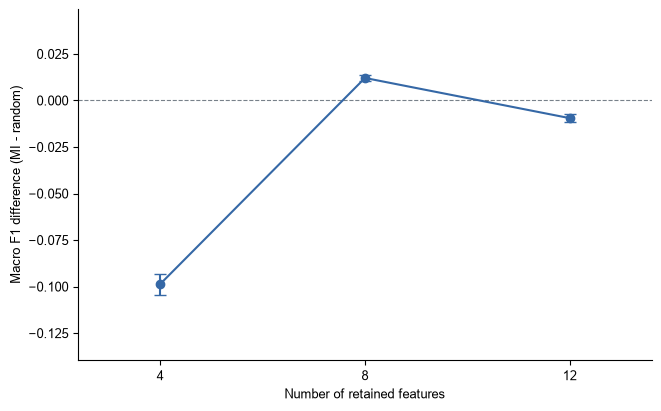

In [11]:
difference_summary = paired_scores.groupby("feature_count")["difference"].agg(["mean", "std"])
figure, axis = plt.subplots(figsize=(6.5, 4.0), layout="constrained")
axis.axhline(0, color="#78818A", linestyle="--", linewidth=0.8)
axis.errorbar(difference_summary.index, difference_summary["mean"], yerr=difference_summary["std"],
              fmt="o-", color="#3568A6", capsize=4)
axis.set(xlabel="Number of retained features", ylabel="Macro F1 difference (MI - random)", xticks=[4, 8, 12])
axis.margins(x=0.2, y=0.3)
save_figure(figure, "random_feature_comparison.png")
plt.show()

## 8. 特征选择是否稳定？

数一数：5个训练折中，每个特征被选中过几次。颜色越深表示越常被选中。还计算Jaccard相似度：两个名单的交集数量除以并集数量，1代表名单完全一致。

“经常被选中”不等于“预测效果一定最好”，需要结合前面的分数一起看。

各维数平均Jaccard相似度： {4: np.float64(1.0), 8: np.float64(1.0), 12: np.float64(1.0)}


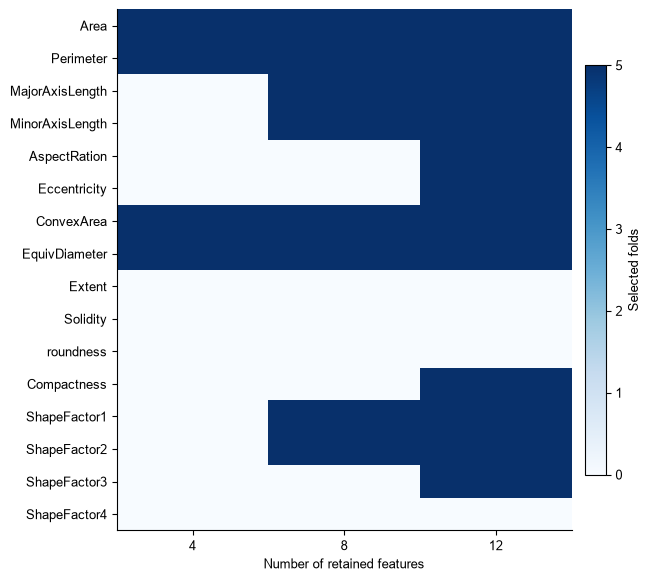

In [12]:
feature_frequency = pd.DataFrame({"feature": feature_names})
stability_scores = {}
for count in [4, 8, 12]:
    feature_frequency[f"top_{count}"] = [sum(name in names for names in selected_feature_sets[count])
                                           for name in feature_names]
    pairs = combinations([set(names) for names in selected_feature_sets[count]], 2)
    stability_scores[count] = [len(first & second) / len(first | second) for first, second in pairs]
save_results(feature_frequency, "feature_selection_frequency.csv")
print("各维数平均Jaccard相似度：", {count: round(np.mean(scores), 3) for count, scores in stability_scores.items()})
figure, axis = plt.subplots(figsize=(6.4, 5.7), layout="constrained")
image = axis.imshow(feature_frequency.iloc[:, 1:].to_numpy(), cmap="Blues", vmin=0, vmax=5, aspect="auto")
figure.colorbar(image, ax=axis, fraction=0.045, pad=0.03, label="Selected folds")
axis.set(xticks=[0, 1, 2], xticklabels=[4, 8, 12], yticks=range(16), yticklabels=feature_names,
         xlabel="Number of retained features")
save_figure(figure, "feature_selection_frequency.png")
plt.show()

## 9. 最后才评价测试集

现在参数和特征数已经确定。各模型在整个开发集重新拟合，再评价固定测试集。只报告结果，不按测试分数改模型。保留RF和Dummy作为参照。

full表示16特征，selected表示前面按验证规则选出的特征数。之后的预测重算只用于检查文件，没有再次训练。

In [13]:
test_models = {"LR_full": ("LR", 16), "LR_selected": ("LR", selected_counts["LR"]),
               "KNN_full": ("KNN", 16), "KNN_selected": ("KNN", selected_counts["KNN"]),
               "RF": ("RF", 16), "Dummy": ("Dummy", 16)}
test_records, prediction_tables, final_models, final_predictions = [], [], {}, {}
with threadpool_limits(limits=2):
    for label, (model_name, count) in test_models.items():
        model = create_model(model_name, None if count == 16 else count)
        model.fit(features_development, labels_development)
        predicted = model.predict(features_test)
        final_models[label], final_predictions[label] = model, predicted
        test_records.append({"model": label, "feature_count": count,
            "accuracy": accuracy_score(labels_test, predicted),
            "macro_f1": f1_score(labels_test, predicted, average="macro")})
        prediction_tables.append(pd.DataFrame({"model": label, "sample_id": labels_test.index,
            "true_class": labels_test.to_numpy(), "predicted_class": predicted}))
        log_progress(f"测试完成：{label}，{count}个特征")
test_results = pd.DataFrame(test_records)
save_results(test_results, "test_results.csv")
save_results(pd.concat(prediction_tables, ignore_index=True), "test_predictions.csv")
display(test_results.round(4))

测试完成：LR_full，16个特征
测试完成：LR_selected，16个特征
测试完成：KNN_full，16个特征
测试完成：KNN_selected，16个特征
测试完成：RF，16个特征
测试完成：Dummy，16个特征


,model,feature_count,accuracy,macro_f1
0,LR_full,16,0.9228,0.9358
1,LR_selected,16,0.9228,0.9358
2,KNN_full,16,0.9225,0.9352
3,KNN_selected,16,0.9225,0.9352
4,RF,16,0.9269,0.9395
5,Dummy,16,0.2617,0.0593


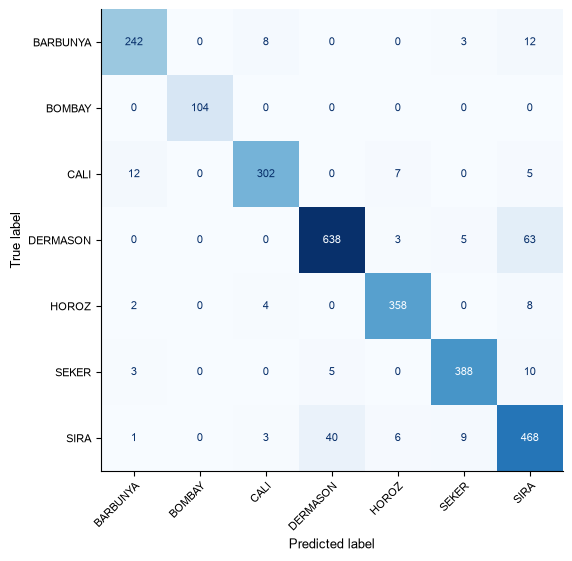

,precision,recall,f1-score,support
BARBUNYA,0.931,0.913,0.922,265.0
BOMBAY,1.000,1.000,1.000,104.0
CALI,0.953,0.926,0.939,326.0
DERMASON,0.934,0.900,0.917,709.0
HOROZ,0.957,0.962,0.960,372.0
SEKER,0.958,0.956,0.957,406.0
SIRA,0.827,0.888,0.856,527.0


In [14]:
figure, axis = plt.subplots(figsize=(7.1, 5.5), layout="constrained")
ConfusionMatrixDisplay.from_predictions(labels_test, final_predictions["LR_selected"],
    labels=class_names, display_labels=class_names, cmap="Blues", colorbar=False,
    xticks_rotation=45, ax=axis, text_kw={"fontsize": 8})
plt.setp(axis.get_xticklabels(), ha="right", rotation_mode="anchor", fontsize=8)
plt.setp(axis.get_yticklabels(), fontsize=8)
save_figure(figure, "confusion_matrix.png")
plt.show()
class_report = pd.DataFrame(classification_report(labels_test, final_predictions["LR_selected"],
    output_dict=True, zero_division=0)).T.loc[class_names]
save_results(class_report.rename_axis("class_name").reset_index(), "classification_report.csv")
display(class_report.round(3))

## 10. 保存一个模型，并尝试预测

只保存本作业用于演示的LR精简管线。加载后输入原始16列，管线会自动执行之前学到的标准化和选列，不需要再训练。这里拿测试集前5行演示预测，不把它们拿去调参。

In [15]:
selected_model = final_models["LR_selected"]
selector = selected_model.named_steps.get("select")
chosen_features = np.array(feature_names)[selector.get_support()].tolist() if selector is not None else feature_names
model_file = models_directory / "bean_classifier.joblib"
joblib.dump({"pipeline": selected_model, "feature_names": feature_names, "selected_features": chosen_features}, model_file)
loaded_model = joblib.load(model_file)
example_features = features_test.head(5)
example_predictions = loaded_model["pipeline"].predict(example_features)
display(pd.DataFrame({"真实类别": labels_test.head(5), "预测类别": example_predictions}))
print("实际使用的特征：", chosen_features)
print("保存模型：", model_file.name)

,真实类别,预测类别
sample_id,,
10032,SIRA,SIRA
9766,SIRA,SIRA
868,SEKER,SEKER
5084,CALI,CALI
1851,SEKER,SEKER


实际使用的特征： ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']
保存模型： bean_classifier.joblib


In [16]:
# 保留简单的参数和复现说明；详细指标已经写在CSV中。
from importlib.metadata import version
experiment_settings.update({"status": "complete", "validation_fits": len(validation_records) + len(random_records),
    "test_models": len(test_records), "selected_features": chosen_features,
    "jaccard_scores": stability_scores, "elapsed_seconds": time.perf_counter() - started_at,
    "versions": {name: version(name) for name in ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "joblib"]},
    "reproduce": "在相同依赖版本下，打开dry_bean_classification.ipynb，保留上面的固定参数，从头全部运行。"})
settings_path.write_text(json.dumps(experiment_settings, ensure_ascii=False, indent=2), encoding="utf-8")
log_progress(f"本次完成：{experiment_settings['validation_fits']}次验证拟合，6个测试方案，耗时{experiment_settings['elapsed_seconds']:.1f}秒")
print("完成。图在results/figures，指标在results中的CSV，说明在README。")

本次完成：85次验证拟合，6个测试方案，耗时30.1秒
完成。图在results/figures，指标在results中的CSV，说明在README。
